In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'KBa'
gitlab_user = 'konrad.baczynski'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-e49f9f2f-eaaa-41c5-8300-dd90ab4fa56b;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# KBa

In [2]:
user_issues(ts_user).toPandas()

25/05/29 09:37:13 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10698,[Uniswap] Oszacowanie kosztu podłączenia marke...,Done,Story,High,None,None,2025-05-27 11:49:03.467,6.5,6.5
1,CRYP-10693,Server ccxt2-975 padł,Delivery,Bug,Highest,None,None,2025-05-27 05:26:24.780,19.0,19.0
2,CRYP-10716,Zmiana principal w strategiach,Delivered,Story,Highest,None,None,2025-05-26 13:16:32.586,4.5,4.5
3,CRYP-9913,[platform-admin] Błędne uprawnienia credential...,Delivered,Bug,Medium,XS,1,2025-05-26 09:30:13.981,6.5,6.5
4,CRYP-10633,Market Data Recorder - serializacja konsumpcji...,Delivered,Bug,Medium,XS,1,2025-05-26 06:34:57.325,7.0,7.0
5,CRYP-10651,"[Onetrading] ERROR ""Java heap space""",Delivered,Bug,High,XS,1,2025-05-26 06:22:04.732,7.5,7.5
6,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Done,Story,Medium,M,5,2025-05-22 12:38:16.560,103.0,2.5
7,CRYP-10690,[Binance] Usunięcie starych feedów,In testing,Bug,Medium,None,None,2025-05-22 11:06:47.384,0.5,0.5
8,CRYP-10580,[Hurtownia danych] Migracja danych COEFFICIENT...,Delivered,Story,Medium,M,5,2025-05-13 12:30:11.766,25.0,25.0
9,CRYP-10556,[Backtest] Zasilenie danych historycznych od p...,Done,Story,High,M,5,2025-05-13 06:11:32.732,23.0,23.0


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-05-01,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Done,2.5
1,2025-05-01,CRYP-10556,[Backtest] Zasilenie danych historycznych od p...,Done,17.5
2,2025-05-01,CRYP-10633,Market Data Recorder - serializacja konsumpcji...,Delivered,1.5
3,2025-05-01,CRYP-10651,"[Onetrading] ERROR ""Java heap space""",Delivered,7.5
4,2025-05-01,CRYP-10658,[Liquidty Calculator] Wartości pól w różnych o...,In Progress,27.0
5,2025-05-01,CRYP-10690,[Binance] Usunięcie starych feedów,In testing,0.5
6,2025-05-01,CRYP-10693,Server ccxt2-975 padł,Delivery,19.0
7,2025-05-01,CRYP-10698,[Uniswap] Oszacowanie kosztu podłączenia marke...,Done,6.5
8,2025-05-01,CRYP-10716,Zmiana principal w strategiach,Delivered,4.5
9,2025-05-01,CRYP-9913,[platform-admin] Błędne uprawnienia credential...,Delivered,6.5


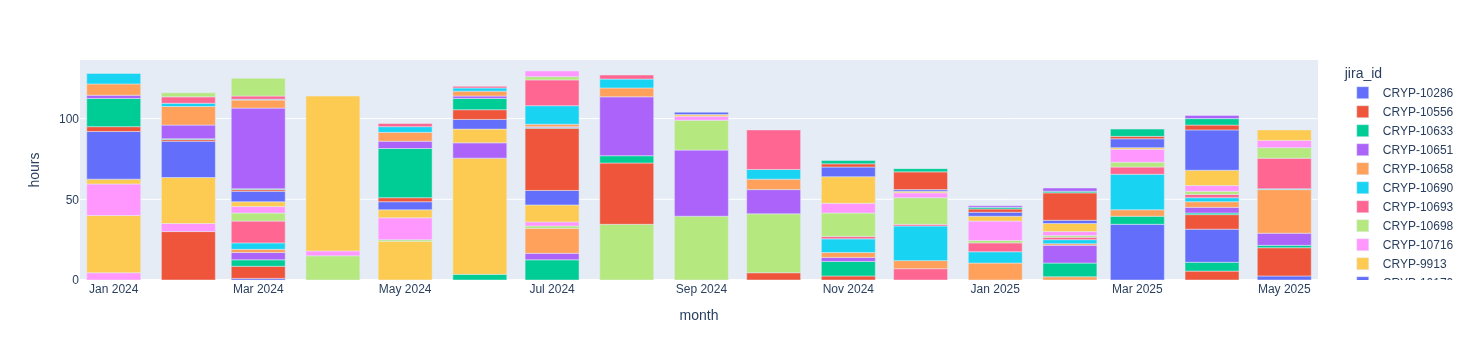

In [4]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

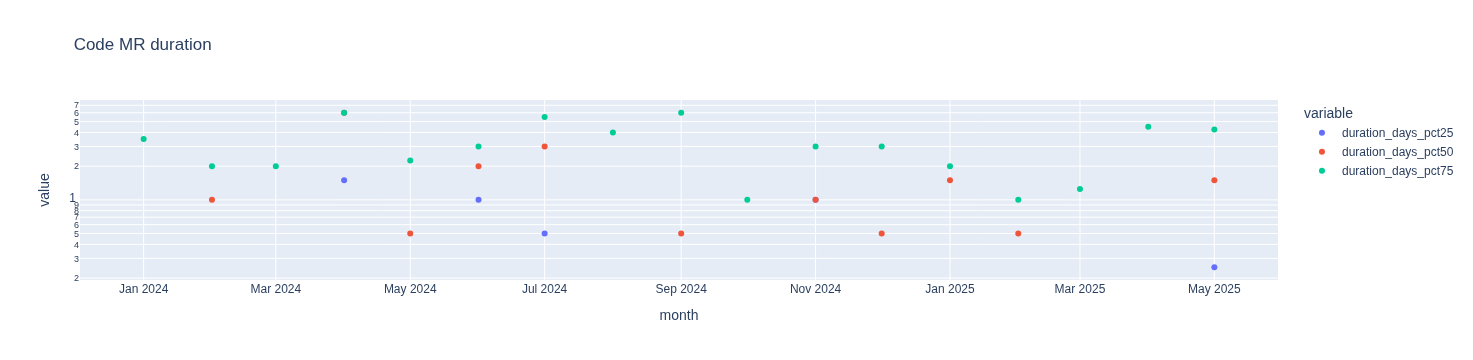

In [9]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

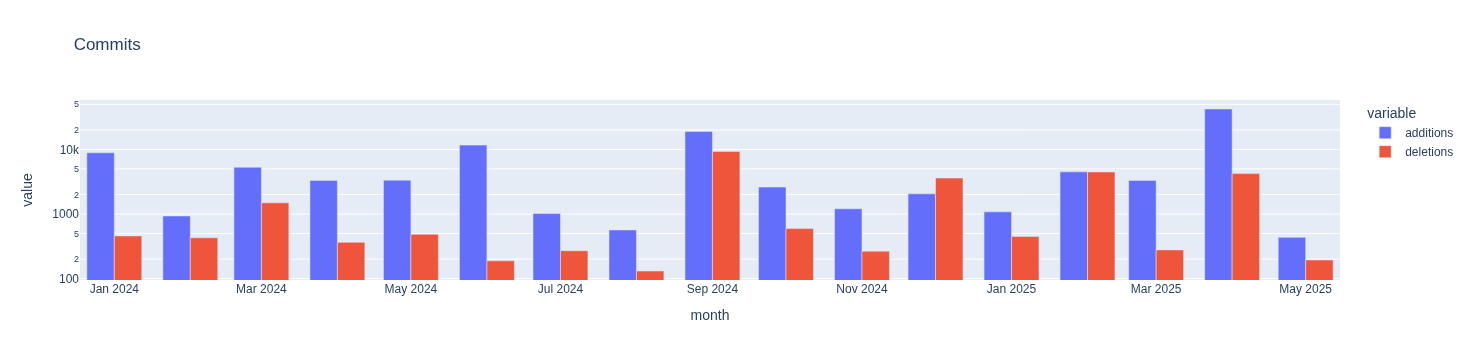

In [10]:
px.bar(user_code_commits(gitlab_user).toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [7]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-05-01,KBa,93.0,51.5,144.5,35.640138
1,2025-04-01,KBa,102.0,68.0,170.0,40.000000
2,2025-03-01,KBa,93.5,66.5,160.0,41.562500
3,2025-02-01,KBa,57.0,48.0,105.0,45.714286
4,2025-01-01,KBa,46.0,42.0,88.0,47.727273
5,2024-12-01,KBa,69.0,75.0,144.0,52.083333
6,2024-11-01,KBa,74.0,70.0,144.0,48.611111
7,2024-10-01,KBa,93.0,84.0,177.0,47.457627
8,2024-09-01,KBa,104.0,48.0,152.0,31.578947
9,2024-08-01,KBa,127.0,41.0,168.0,24.404762


In [8]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-05-01,Konsultacje z zespołem devops,1.0
1,2025-05-01,Code review,7.0
2,2025-05-01,Spotkania projektowe,17.5
3,2025-05-01,1:1,1.0
4,2025-05-01,Release Manager,14.5
5,2025-05-01,Wsparcie produkcji liquee,1.0
6,2025-05-01,Konsultacje z zespołem dev,7.0
7,2025-05-01,Konsultacje z zespołem testerskim,2.5
8,2025-04-01,Konsultacje z zespołem data science,0.5
9,2025-04-01,Konsultacje z zespołem dev,4.5
